<table style="border:none;width:100%;table-layout:fixed"><tr style="border:none">
<td style="border:none;text-align:left;vertical-align:middle">
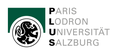</td>
<td style="border:none;text-align:center;vertical-align:middle">
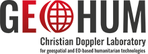</td>
<td style="border:none;text-align:right;vertical-align:middle">
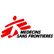</td>
</tr></table>

---

# High-Resolution Urban Heat Mapping - Tondo, Manila
## 01 · Pipeline - produce the maps

**Christian Doppler Laboratory GEOHUM** - geospatial and EO-based humanitarian technologies
Department of Geoinformatics (Z_GIS), Paris Lodron University of Salzburg · in partnership with **Médecins Sans Frontières**

---

Runs the full pipeline for one acquisition mode and writes every product.

**Run this notebook twice**: once with `MODE = "Day"`, once with `MODE = "Night"`. Everything downstream reads the results from disk, so the order does not matter.

The processing itself lives in the `lstpipe` package. Each step below is one call; open the module named in the heading to read what it does and why.

## Setup

In [1]:
import sys
from pathlib import Path

# lstpipe lives beside this notebook or one level up
for _c in (Path.cwd(), Path.cwd().parent):
    if (_c / "lstpipe").is_dir():
        sys.path.insert(0, str(_c))
        break

import lstpipe
from lstpipe import Config
print("lstpipe", lstpipe.__version__)

lstpipe 2.0.1


## Authentication

ECOSTRESS is distributed through NASA Earthdata. Searching the catalogue is open, but streaming and downloading files require credentials, so a missing login surfaces late - the search succeeds and the first file access fails.

`persist=True` writes the credentials to `~/.netrc`, so later sessions authenticate silently. The pipeline also calls this itself if you skip the cell.

In [2]:
import earthaccess

auth = earthaccess.login(persist=True)
print("Earthdata login:", "active" if auth and auth.authenticated else "FAILED")

Enter your Earthdata Login username:  getchearthdata
Enter your Earthdata password:  ········


Earthdata login: active


## Configuration

Every tunable setting lives in one `Config` object - study area, thresholds, model parameters, output paths. Change it here and nothing else needs editing.

Directories are created immediately using absolute paths, so a run cannot write somewhere unexpected.

In [3]:
MODE = "Day"          # <-- switch to "Night" and re-run for the night product

cfg = Config.manila(mode=MODE, start="2024-01-01", end="2026-12-31")
print(cfg.summary())
print("outputs ->", cfg.base_dir)

manila · Day · 2024-01-01 to 2026-12-31
  bbox (120.9, 14.55, 121.04, 14.7) | EPSG:32651
  local windows 06-18h | quality threshold 0.3
  70 m -> 10 m | S2 window ±15 d
  outputs C:\BUCKET\Advising\Khalid\manila-lst-downscaling
outputs -> C:\BUCKET\Advising\Khalid\manila-lst-downscaling


## Run

`run_pipeline` performs acquisition, harvesting, training, mapping and compositing. Expect hours for a multi-year archive: the time goes into streaming every granule for screening, and into fetching a separate Sentinel-2 composite for each overpass.

**This is the only notebook that downloads anything.** It writes a screening manifest, a harvest cache and the fitted model, from which every later notebook restores in seconds. To force a fresh run after changing the configuration, pass `rebuild=True`.

To work step by step instead - inspecting the intermediates - see notebook `01b`.

In [4]:
result = lstpipe.run_pipeline(cfg)


1. ACQUISITION
granules intersecting manila: 287

window 06-18h local


QUEUEING TASKS | :   0%|          | 0/4 [00:00<?, ?it/s]

PROCESSING TASKS | :   0%|          | 0/4 [00:00<?, ?it/s]

COLLECTING RESULTS | :   0%|          | 0/4 [00:00<?, ?it/s]

    2024-01-03 2354UTC (07h local) valid 0.69


QUEUEING TASKS | :   0%|          | 0/4 [00:00<?, ?it/s]

... (257 outputs left out)

COLLECTING RESULTS | :   0%|          | 0/4 [00:00<?, ?it/s]

    2026-10-08 2206UTC (06h local) valid 0.64

Day: 66 scenes downloaded (75 below quality threshold, 0 download failures)

2. REFERENCE GRIDS AND STATIC LAYERS
grids: 70 m (240, 218) | 10 m (1674, 1524)
DEM: -0–60 m
land cover: (1800, 1681) -> (240, 218) / (1674, 1524)

3. PER-SCENE HARVEST
Day: harvesting from 66 overpasses

  [2/66] 2024-01-03_2354: 20,000 samples · S2 gap 1 d · 51 dead lines filled
  [3/66] 2024-01-12_0958: 20,000 samples · S2 gap 0 d · 50 dead lines filled
  [4/66] 2024-01-16_0823: 20,000 samples · S2 gap 4 d · 50 dead lines filled


C:\Users\b1077653\Anaconda\envs\marimo\Lib\site-packages\rasterio\warp.py:390: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dest = _reproject(


  [6/66] 2024-03-17_0831: 20,000 samples · S2 gap 10 d · 50 dead lines filled
  [8/66] 2024-06-11_0839: 20,000 samples · S2 gap 4 d · 51 dead lines filled
  [10/66] 2024-07-07_2216: 20,000 samples · S2 gap 7 d · 94 dead lines filled
  [11/66] 2024-07-31_0242: 20,000 samples · S2 gap 4 d · 49 dead lines filled
  [12/66] 2024-08-30_0119: 20,000 samples · S2 gap 1 d · 64 dead lines filled
  [15/66] 2024-10-08_2255: 20,000 samples · S2 gap 5 d · 52 dead lines filled
  [19/66] 2024-12-07_2314: 20,000 samples · S2 gap 15 d · 51 dead lines filled
  [25/66] 2025-03-16_0813: 20,000 samples · S2 gap 2 d · 95 dead lines filled
  [27/66] 2025-04-07_2324: 20,000 samples · S2 gap 9 d · 50 dead lines filled
  [29/66] 2025-04-15_0656: 20,000 samples · S2 gap 11 d · 50 dead lines filled
  [30/66] 2025-04-23_0344: 20,000 samples · S2 gap 3 d · 51 dead lines filled
  [31/66] 2025-04-27_0210: 20,000 samples · S2 gap 1 d · 51 dead lines filled
  [33/66] 2025-08-01_0138: 20,000 samples · S2 gap 3 d · 75 dea

## What was produced

manila · Day
  35 scenes · 682,769 samples
  pattern  MAE 2.39 K · RMSE 3.63 K · R² 0.142
absolute MAE 2.39 K · RMSE 3.63 K · R² 0.794   (same error, larger denominator)
  35 maps -> C:\BUCKET\Advising\Khalid\manila-lst-downscaling\products\per_scene_day


,date,utc,mode,local_hour,s2_gap_days,coverage,sharpened_frac,scene_mean_C,mean_C,p95_C,file_10m
0,2024-01-03,2354,Day,7,1.0,0.60,1.0,28.99,28.99,31.49,C:\BUCKET\Advising\Khalid\manila-lst-downscali...
1,2024-01-12,0958,Day,17,0.0,0.63,1.0,26.58,26.58,28.26,C:\BUCKET\Advising\Khalid\manila-lst-downscali...
2,2024-01-16,0823,Day,16,4.0,0.63,1.0,33.02,33.03,34.89,C:\BUCKET\Advising\Khalid\manila-lst-downscali...
3,2024-03-17,0831,Day,16,10.0,0.61,1.0,33.12,33.12,35.33,C:\BUCKET\Advising\Khalid\manila-lst-downscali...
4,2024-06-11,0839,Day,16,4.0,0.63,1.0,39.45,39.45,42.15,C:\BUCKET\Advising\Khalid\manila-lst-downscali...
5,2024-07-07,2216,Day,6,7.0,0.52,1.0,35.51,35.51,46.62,C:\BUCKET\Advising\Khalid\manila-lst-downscali...
6,2024-07-31,0242,Day,10,4.0,0.63,1.0,44.19,44.20,51.24,C:\BUCKET\Advising\Khalid\manila-lst-downscali...
7,2024-08-30,0119,Day,9,1.0,0.60,1.0,41.34,41.34,49.55,C:\BUCKET\Advising\Khalid\manila-lst-downscali...
8,2024-10-08,2255,Day,6,5.0,0.63,1.0,27.18,27.19,28.68,C:\BUCKET\Advising\Khalid\manila-lst-downscali...
9,2024-12-07,2314,Day,7,15.0,0.63,1.0,26.05,26.05,28.04,C:\BUCKET\Advising\Khalid\manila-lst-downscali...


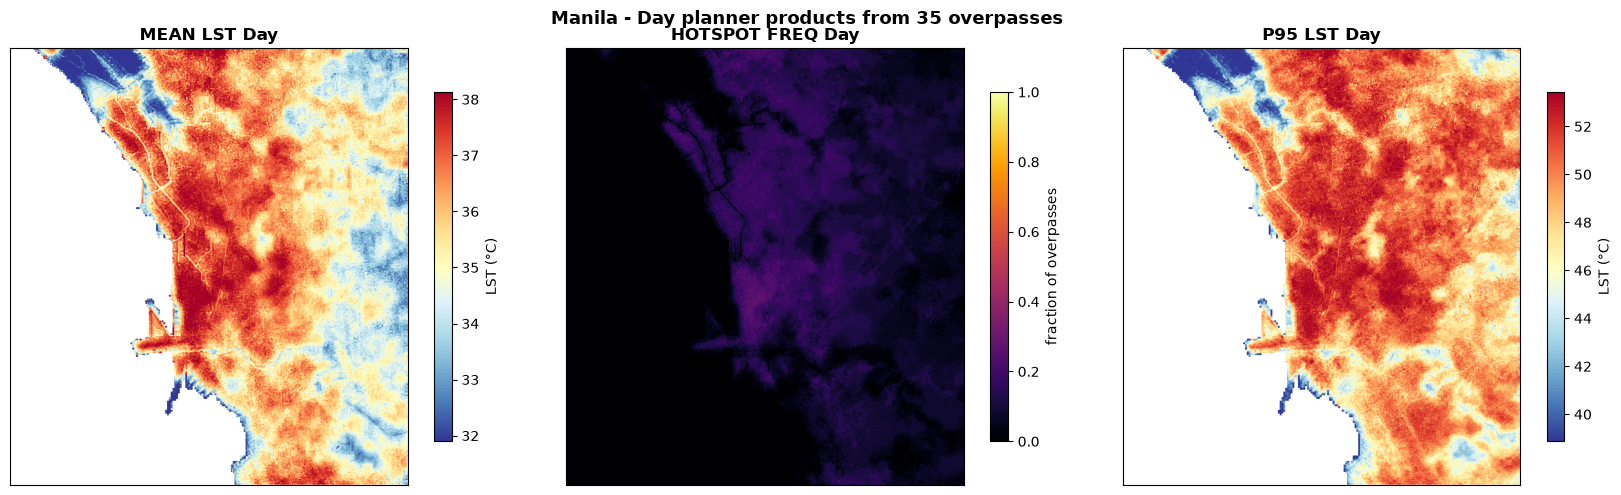

In [5]:
from lstpipe import viz

print(result.summary())
display(result.inventory.head(10))

if result.composites:
    viz.planner_products(cfg, result.composites)

## Hot-day layers

Exceedance counts per year and their trend.

**Interpretation caveat.** ECOSTRESS samples instantaneous overpass temperature at varying local hours, not a daily mean, and the archive is irregular. Year-to-year differences track which overpasses happened to be cloud-free far more strongly than any climate signal. Report these as *days on which an observed overpass exceeded the threshold*, pooled across years.

In [6]:
from lstpipe import products

hot = products.hot_days(cfg)

  2024: 10 scenes · mean 122 days/yr above 35 °C
  2025: 7 scenes · mean 233 days/yr above 35 °C
  2026: 18 scenes · mean 160 days/yr above 35 °C

trend significant at p<0.05 for 5,482 pixels (0.3 % of testable)
  only 3 years - treat the trend as indicative and lead with the per-year and mean layers


---

**Next.** Once both Day and Night have been run, continue with `02_validation.ipynb`.